In [2]:
import pymongo
from pymongo import MongoClient

In [3]:
conn=pymongo.MongoClient("mongodb://localhost:27017/")['backdoor']

## GTSB BadNets -> BTSC Finetuning

In [4]:
tm2_gtsb_badnet = list(conn['tm2_v3_TEST:badnet'].find({}))
tm2_btsc_badnet = list(conn['tm2_v3_btsc_badnet:finetune'].find({}))

In [5]:
list(conn['tm2_v3_btsc_badnet:finetune'].find({'original_model': 'weights/gtsb_badnet/tm2_v3_TEST:badnet_0.003924958814704682_80a67f.pth'}))

[{'_id': ObjectId('68c8d3fe6e8cec0153d2e316'),
  'args': {'prefix': 'tm2_v3_btsc_badnet',
   'dataset': 'BTSC',
   'trials': 1,
   'seed': 0,
   'load_model': 'weights/gtsb_badnet/tm2_v3_TEST:*.pth',
   'trigger': "checkerboard('bottomleft', (3, 3), colours=(255, 0))",
   'backdoor_class': 6,
   'mongo_url': 'mongodb://localhost:27017/',
   'weights_path': 'weights/badnet_finetuning',
   'epochs': 20,
   'learning_rate': 0.1,
   'device': 'cuda',
   'no_batchnorm': False,
   'use_wandb': False,
   'no_annealing': False,
   'no_dataaug': False},
  'history': [{'train_stats': {'train_eval_loss': 0.11196092795923113,
     'train_eval_acc': 0.9657853810264385},
    'test_stats': {'test_eval_loss': 0.4450207102548011,
     'test_eval_acc': 0.8836452400325467},
    'test_bd_stats': {'test_bd_loss': 2.8495255346046995,
     'test_bd_acc': 0.49389747762408465},
    'test_bd_neg_stats': {'test_bd_neg_loss': 2.344045654169615,
     'test_bd_neg_acc': 0.5036615134255492}},
   {'train_stats': {'tr

In [6]:
tm2_btsc_badnet[0]['original_model']

'weights/gtsb_badnet/tm2_v3_TEST:badnet_0.003924958814704682_80a67f.pth'

In [7]:
data = []

for model in tm2_gtsb_badnet:
    if not model['success']:
        print('failed')
        continue
    
    res = model['result']
    
    # Find the associate finetuned result
    ft_result = list(conn['tm2_v3_btsc_badnet:finetune'].find({'original_model': res['weights']}))
    if len(ft_result) != 1:
        print(len(ft_result), '???')
        continue
        
    ft_res = ft_result[0]['stats']
#     print(ft_res.keys())
    
    
    print(f"{res['test_stats']['test_eval_acc']:.4f} {res['test_bd_stats']['test_bd_acc']:.4f} -> "\
          f"{ft_res['test_stats']['test_eval_acc']:.4f} {ft_res['test_bd_stats']['test_bd_acc']:.4f}")
    
    data.append([
        res['test_stats']['test_eval_acc'],
        res['test_bd_stats']['test_bd_acc'],
        ft_res['test_stats']['test_eval_acc'],
        ft_res['test_bd_stats']['test_bd_acc']
    ])
#     break

0.9759 0.9998 -> 0.9675 0.0464
0.9748 1.0000 -> 0.9691 0.1237
0.9785 1.0000 -> 0.9813 0.9919
0.9810 1.0000 -> 0.9626 0.7152
0.9746 1.0000 -> 0.9504 0.9178
0.9609 0.9112 -> 0.9805 0.0212
0.9718 1.0000 -> 0.9471 0.0724
0.9810 0.9902 -> 0.9845 0.0260
0.9832 0.9998 -> 0.9878 0.2791
0.9779 0.9994 -> 0.9797 0.3995
0.9798 1.0000 -> 0.9780 0.2286
0.9779 1.0000 -> 0.9487 0.5248
0.9845 1.0000 -> 0.9715 0.2010
0.9783 1.0000 -> 0.9618 0.5517
0.9712 1.0000 -> 0.9813 0.9878
0.9646 0.9675 -> 0.9764 0.0212
0.9687 1.0000 -> 0.9544 0.2042
0.9822 0.9947 -> 0.9919 0.0407
0.9736 0.9998 -> 0.9691 0.0325
0.9808 1.0000 -> 0.9813 0.2783


In [8]:
import pandas as pd

df = pd.DataFrame(data)
df.columns = ['gtsb_acc', 'gtsb_bd', 'btsc_acc', 'btsc_bd']
df.head()

,gtsb_acc,gtsb_bd,btsc_acc,btsc_bd
0,0.975869,0.999796,0.967453,0.046379
1,0.974847,1.000000,0.969081,0.123678
2,0.978528,1.000000,0.981286,0.991863
3,0.980982,1.000000,0.962571,0.715216
4,0.974642,1.000000,0.950366,0.917819


<Axes: xlabel='gtsb_acc', ylabel='btsc_acc'>

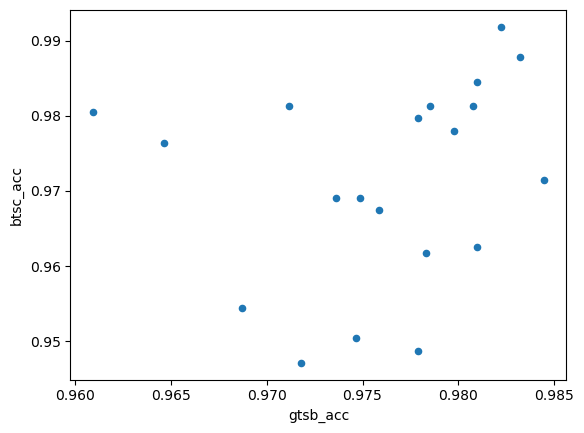

In [9]:
df.plot('gtsb_acc', 'btsc_acc', kind='scatter')

<Axes: xlabel='gtsb_bd', ylabel='btsc_bd'>

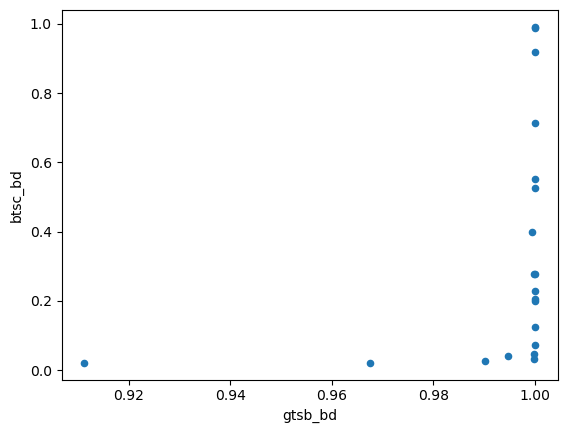

In [10]:
df.plot('gtsb_bd', 'btsc_bd', kind='scatter')

/tmp/ipykernel_2900178/2682989243.py:14: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[0].set_yticklabels([f'{y*100:.0f}%' for y in ax[0].get_yticks()])


[Text(0, 0.8, '80%'),
 Text(0, 0.8500000000000001, '85%'),
 Text(0, 0.9, '90%'),
 Text(0, 0.9500000000000001, '95%'),
 Text(0, 1.0, '100%')]

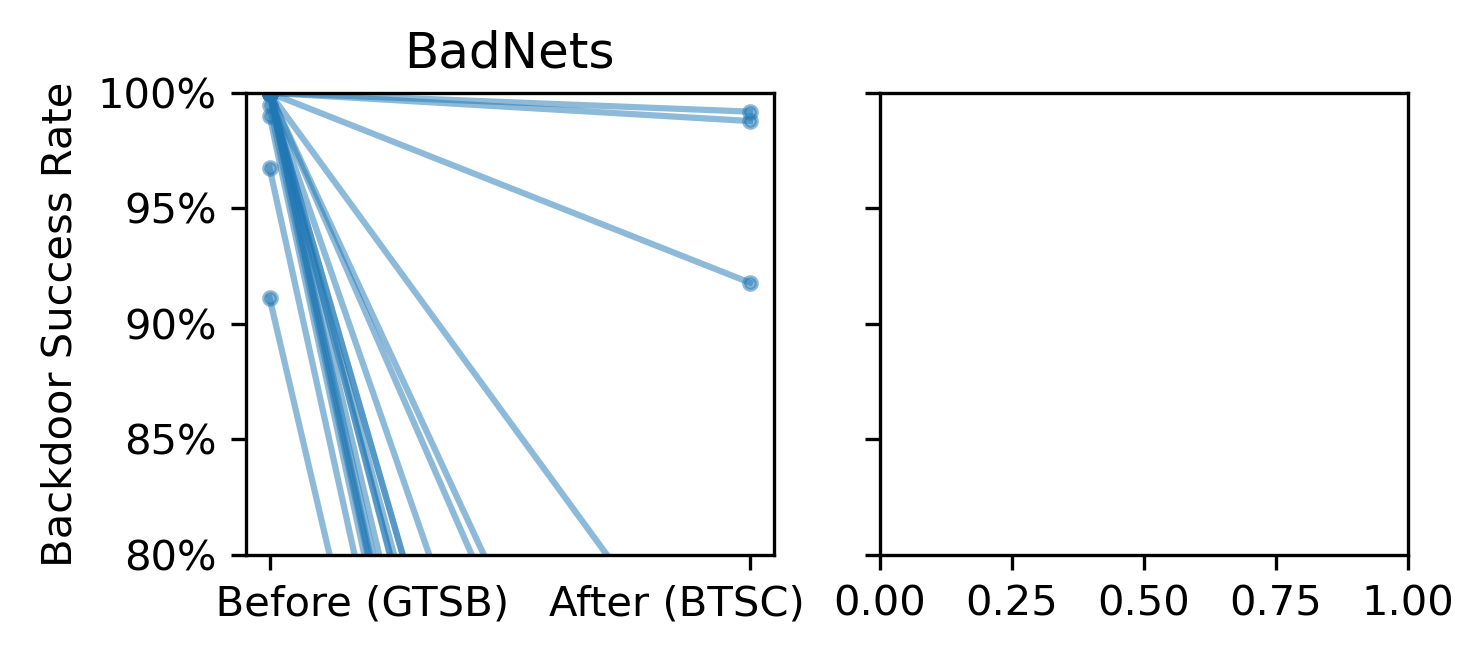

In [11]:
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['figure.dpi'] = 300

fig, ax = plt.subplots(1, 2, sharey=True, figsize=(5, 2))
for _,row in df.iterrows():
    ax[0].plot([0, 1], [row['gtsb_bd'], row['btsc_bd']], alpha=0.5, c='tab:blue', marker='.')
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(['              Before (GTSB)', 'After (BTSC)           '])
ax[0].set_ylabel('Backdoor Success Rate')
ax[0].set_title('BadNets')
ax[0].set_ylim(0.8, 1.0)
ax[0].set_yticklabels([f'{y*100:.0f}%' for y in ax[0].get_yticks()])

## GTSB Handcrafted -> BTSC Finetuning

In [12]:
tm2_gtsb_handcrafted = list(conn['tm2_v3:handcrafted'].find({}))
tm2_btsc_handcrafted = list(conn['tm2_v3_btsc_handcrafted:finetune'].find({}))

In [13]:
# 检查前几个成功的模型，看看 result 里面的结构
count = 0
for model in tm2_gtsb_handcrafted:
    if not model['success']:
        continue
    
    res = model['result']
    print("==== Model Result Keys ====")
    print(res.keys())          # 打印所有键
    print(res)                 # 打印完整字典内容（可能比较长）
    print("==========================\n")
    
    count += 1
    if count >= 2:   # 只看前 2 个，避免输出太多
        break


==== Model Result Keys ====
dict_keys(['train_stats', 'test_stats', 'test_bd_stats', 'test_bd_neg_stats', 'weights/gtsb_handcrafted/tm2_v3:handcrafted_e20660.pth', 'args'])
{'train_stats': {'train_eval_loss': 0.00024350515661124313, 'train_eval_acc': 1.0}, 'test_stats': {'test_eval_loss': 0.07117996621412247, 'test_eval_acc': 0.9801635991820041}, 'test_bd_stats': {'test_bd_loss': 14.769702994067732, 'test_bd_acc': 0.07791411042944785}, 'test_bd_neg_stats': {'test_bd_neg_loss': 0.06840040478969645, 'test_bd_neg_acc': 0.9793456032719836}, 'weights/gtsb_handcrafted/tm2_v3:handcrafted_e20660.pth': 'weights/gtsb_handcrafted/tm2_v3:handcrafted_e20660.pth', 'args': {'task': ['handcrafted'], 'prefix': 'tm2_v3', 'dataset': 'GTSB', 'trigger': "checkerboard('bottomleft', (3, 3), colours=(255, 0))", 'backdoor_class': 6, 'trials': 7, 'seed': 0, 'handcrafted_clean_weights': 'weights/gtsb_clean/tm2_v3:clean_1d0346.pth', 'mongo_url': 'mongodb://localhost:27017/', 'weights_path': 'weights/gtsb_handcraf

In [14]:
data = []

for model in tm2_gtsb_handcrafted:
    if not model['success']:
        print('failed')
        continue
    
    res = model['result']
    
    weight_key = [k for k in res.keys() if k.startswith("weights/")]
    if len(weight_key) != 1:
        print("Unexpected weight keys:", weight_key)
        continue

    weight_path = res[weight_key[0]]  # 取出真正的路径


    # Find the associate finetuned result
    ft_result = list(conn['tm2_v3_btsc_handcrafted:finetune'].find({'original_model': weight_path}))
    if len(ft_result) != 1:
        print(len(ft_result), '???')
        continue
        
    ft_res = ft_result[0]['stats']
#     print(ft_res.keys())
    
    
    print(f"{res['test_stats']['test_eval_acc']:.4f} {res['test_bd_stats']['test_bd_acc']:.4f} -> "\
          f"{ft_res['test_stats']['test_eval_acc']:.4f} {ft_res['test_bd_stats']['test_bd_acc']:.4f}")
    
    data.append([
        res['test_stats']['test_eval_acc'],
        res['test_bd_stats']['test_bd_acc'],
        ft_res['test_stats']['test_eval_acc'],
        ft_res['test_bd_stats']['test_bd_acc']
    ])
#     break

0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0.9552 0.9211 -> 0.9463 0.0212
0 ???
failed
0 ???
0 ???
failed
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0.8998 0.9419 -> 0.9422 0.0203
0 ???
0.9252 0.8061 -> 0.9585 0.0212
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0.9317 0.9479 -> 0.9634 0.0203
0.9082 0.9654 -> 0.9609 0.0220
0.9155 0.9276 -> 0.9260 0.0220
0 ???
0.8573 0.9673 -> 0.9357 0.0220
0.9092 0.8767 -> 0.9439 0.0212
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0 ???
0.8939 0.8601 -> 0.9618 0.0212
0.9065 0.9145 -> 0.9683 0.0212
0.9266 0.9174 -> 0.9479 0.0212
0 ???
0 ???
0.9493 0.9587 -> 0.9243 0.0212
0.9673 0.9967 -> 0.9496 0.0220
0 ???
failed
0 ???
0.8534 0.9787 -> 0.9577 0.0203
0.8830 0.9669 -> 0.9398 0.0203
0.9323 0.9683 -> 0.9536 0.0195
0.9603 0.9881 -> 0.9618 0.0212
0 ???
failed
0.9624 0.9746 -> 0.9341 0.0212
failed
0 ???
0.8898 0.9990 -> 0.9601 0.0203
0.9276 0.9249 -> 0.9471 0.0203
0 ???
0.9650 0.8975 -

In [15]:
df_hc = pd.DataFrame(data)
df_hc.columns = ['gtsb_acc', 'gtsb_bd', 'btsc_acc', 'btsc_bd']
df_hc.head()

,gtsb_acc,gtsb_bd,btsc_acc,btsc_bd
0,0.955215,0.921063,0.946298,0.021155
1,0.899796,0.941922,0.942229,0.020342
2,0.925153,0.806135,0.958503,0.021155
3,0.931697,0.947853,0.963385,0.020342
4,0.908180,0.965440,0.960944,0.021969


<Axes: xlabel='gtsb_bd', ylabel='btsc_bd'>

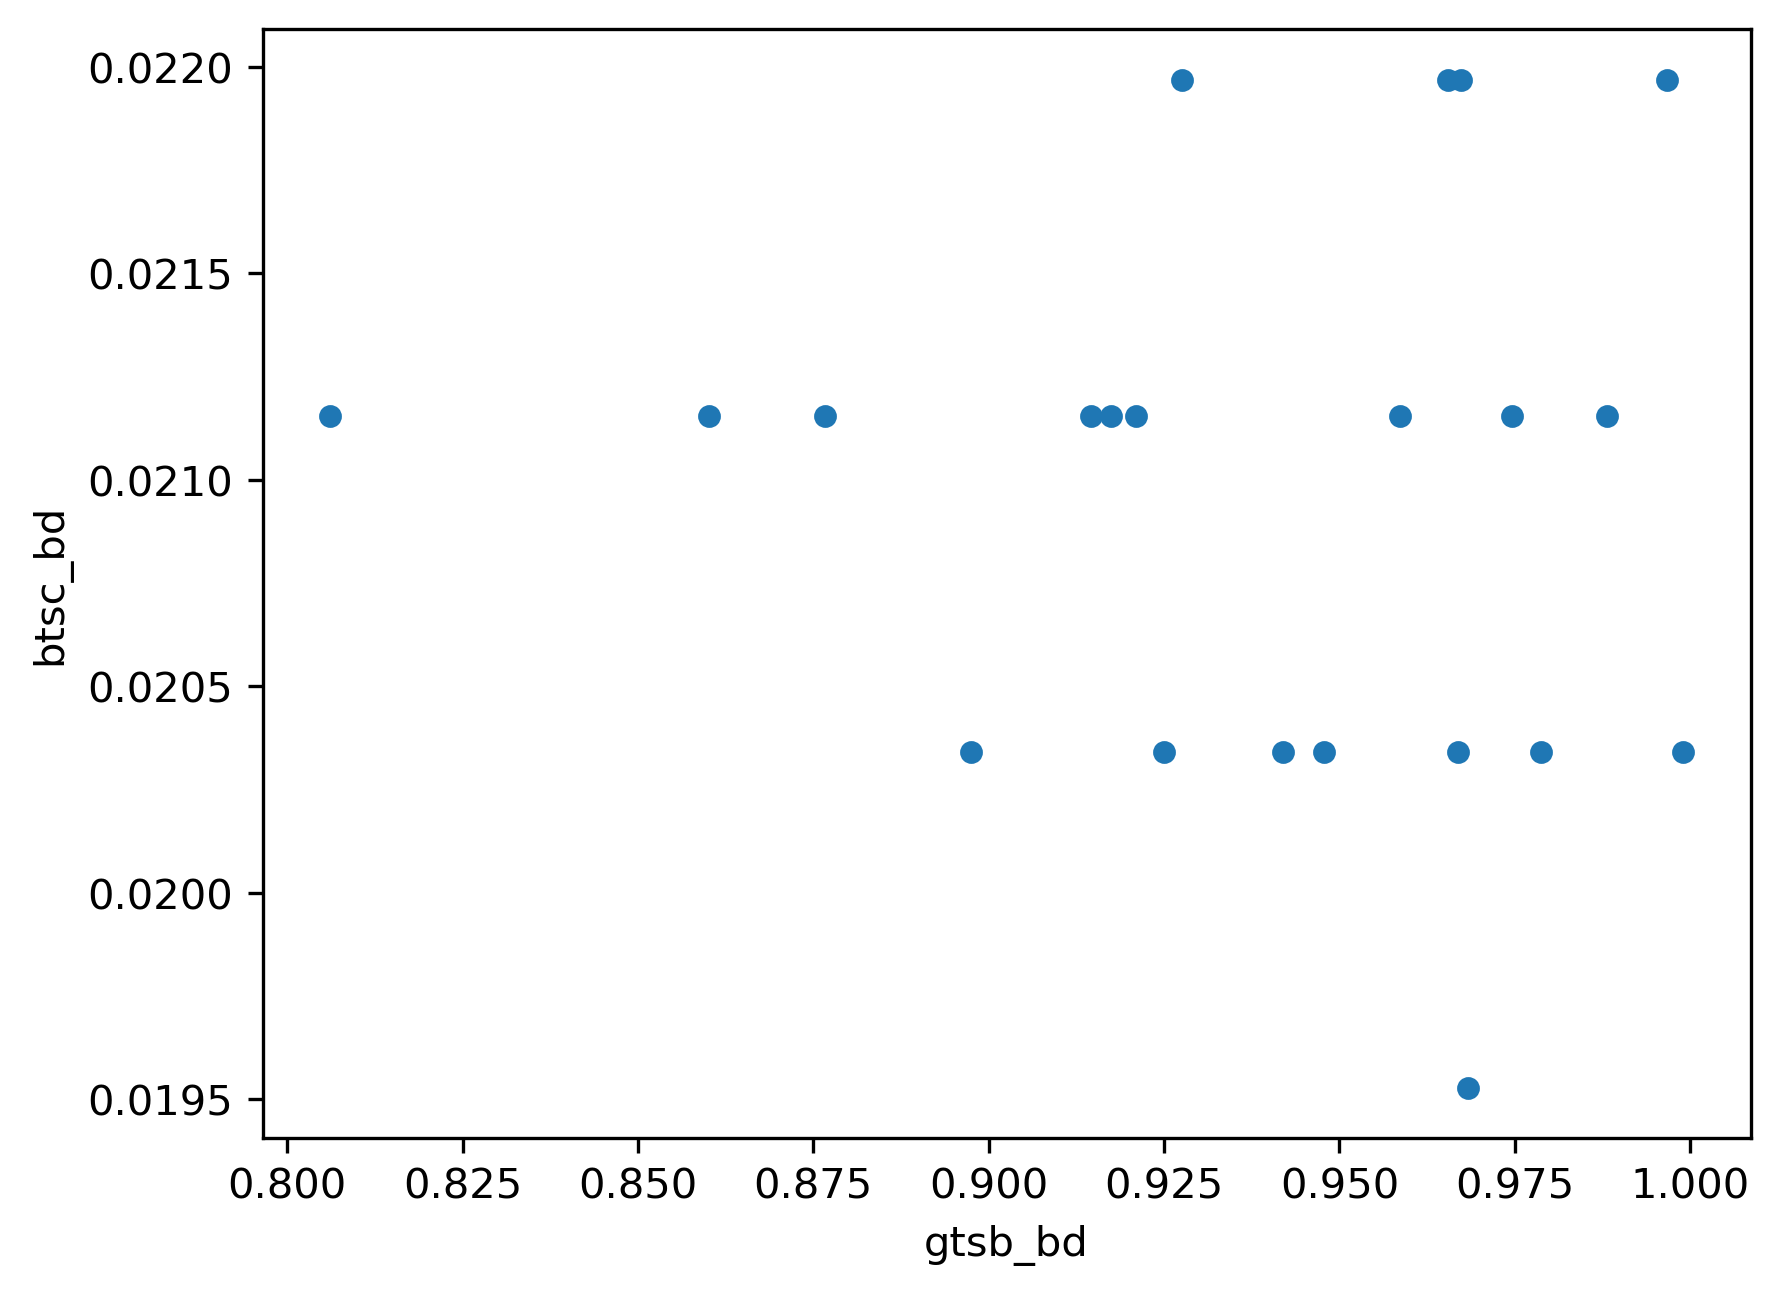

In [16]:
df_hc.plot('gtsb_bd', 'btsc_bd', kind='scatter')

/tmp/ipykernel_2900178/1541067501.py:14: UserWarning: FixedFormatter should only be used together with FixedLocator
  ax[0].set_yticklabels([f'{y*100:.0f}%' for y in ax[0].get_yticks()])


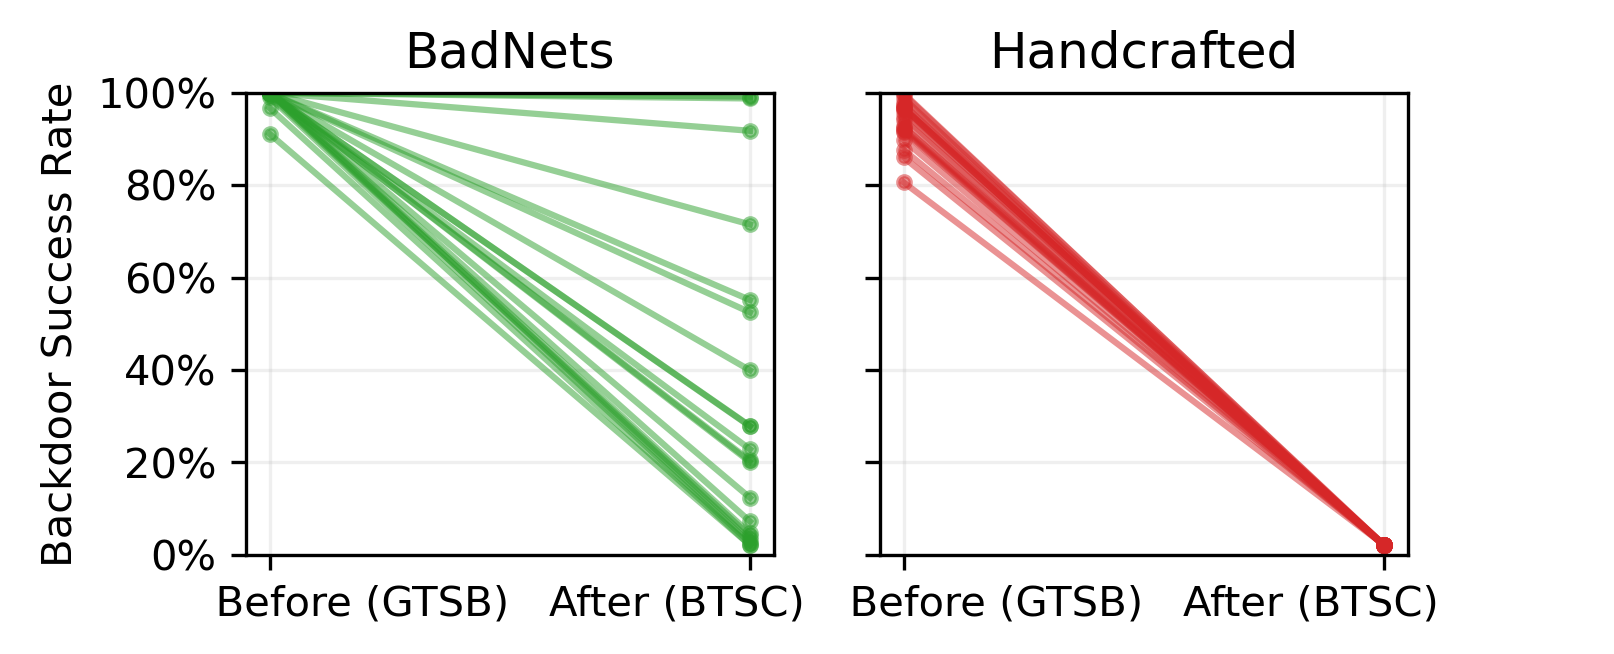

In [17]:
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['figure.dpi'] = 300

fig, ax = plt.subplots(1, 2, sharey=True, figsize=(5, 2))
for _,row in df.iterrows():
    ax[0].plot([0, 1], [row['gtsb_bd'], row['btsc_bd']], alpha=0.5, c='tab:green', marker='.')
ax[0].set_xticks([0, 1])
ax[0].set_xticklabels(['              Before (GTSB)', 'After (BTSC)           '])
ax[0].set_ylabel('Backdoor Success Rate')
ax[0].set_title('BadNets')
ax[0].set_ylim(0, 1.0)
ax[0].set_yticklabels([f'{y*100:.0f}%' for y in ax[0].get_yticks()])

for _,row in df_hc.sort_values('gtsb_acc')[:50].iterrows():
    ax[1].plot([0, 1], [row['gtsb_bd'], row['btsc_bd']], alpha=0.5, c='tab:red', marker='.')
ax[1].set_xticks([0, 1])
ax[1].set_xticklabels(['              Before (GTSB)', 'After (BTSC)           '])
# ax[1].set_ylabel('Backdoor Success Rate')
ax[1].set_title('Handcrafted')
ax[0].grid(alpha=0.2)
ax[1].grid(alpha=0.2)

# ax[0].set_xlim(-0.2, 1.2)
# ax[0].boxplot(df_hc['gtsb_bd'], positions=[0])

# plt.tight_layout()
plt.savefig('tm2_backdoorperf.pdf',bbox_inches='tight')
plt.show()

In [18]:
df_hc['gtsb_bd'].describe()

count    21.000000
mean      0.938076
std       0.048464
min       0.806135
25%       0.917382
50%       0.947853
75%       0.968303
max       0.998978
Name: gtsb_bd, dtype: float64

In [19]:
df['gtsb_bd'].describe()

count    20.000000
mean      0.993119
std       0.020663
min       0.911247
25%       0.999693
50%       1.000000
75%       1.000000
max       1.000000
Name: gtsb_bd, dtype: float64

In [20]:
tm2_btsc_clean_ex = list(conn['tm2_v3_btsc_clean:finetune'].find({}))[0]

def flatten_dict(d):
    d2 = {}
    for v in d.values():
        d2.update(v)
    return d2

# Dummy row - before training statistics
pre_train_stats = {'train_eval_loss': 100, 'train_eval_acc': 0.1, 'test_eval_loss': 100, 'test_eval_acc': 0.1,
       'test_bd_loss': 100, 'test_bd_acc': 0}

tm2_btsc_clean_ex = pd.DataFrame([pre_train_stats] + [flatten_dict(d) for d in tm2_btsc_clean_ex['history']])
tm2_btsc_clean_ex

,train_eval_loss,train_eval_acc,test_eval_loss,test_eval_acc,test_bd_loss,test_bd_acc,test_bd_neg_loss,test_bd_neg_acc
0,100.000000,0.100000,100.000000,0.100000,100.000000,0.000000,NaN,NaN
1,0.103985,0.975117,0.838122,0.871440,20.633705,0.019528,0.827472,0.871440
2,0.002563,0.999482,0.375021,0.909683,17.168947,0.021155,0.370891,0.912124
3,0.021426,0.991706,0.247499,0.926770,16.267879,0.021155,0.244036,0.926770
4,0.002197,0.998963,0.333816,0.915378,15.513339,0.021155,0.324688,0.919447
5,0.000521,1.000000,0.275747,0.927583,15.433577,0.020342,0.269591,0.928397
6,0.000938,0.999482,0.138204,0.952807,15.599115,0.020342,0.134379,0.953621
7,0.000289,1.000000,0.215283,0.938161,15.886367,0.021155,0.208451,0.938161
8,0.000527,1.000000,0.219284,0.936534,15.893508,0.020342,0.212230,0.938161
9,0.000236,1.000000,0.242950,0.932465,15.946072,0.020342,0.234519,0.933279


In [21]:
tm2_btsc_badnet_exs = list(conn['tm2_v3_btsc_badnet:finetune'].find(
    { "stats_pretrain.test_bd_stats.test_bd_acc" : { '$gt' : 0.99 } }
))
tm2_btsc_badnet_exs

[{'_id': ObjectId('68c8d3fe6e8cec0153d2e316'),
  'args': {'prefix': 'tm2_v3_btsc_badnet',
   'dataset': 'BTSC',
   'trials': 1,
   'seed': 0,
   'load_model': 'weights/gtsb_badnet/tm2_v3_TEST:*.pth',
   'trigger': "checkerboard('bottomleft', (3, 3), colours=(255, 0))",
   'backdoor_class': 6,
   'mongo_url': 'mongodb://localhost:27017/',
   'weights_path': 'weights/badnet_finetuning',
   'epochs': 20,
   'learning_rate': 0.1,
   'device': 'cuda',
   'no_batchnorm': False,
   'use_wandb': False,
   'no_annealing': False,
   'no_dataaug': False},
  'history': [{'train_stats': {'train_eval_loss': 0.11196092795923113,
     'train_eval_acc': 0.9657853810264385},
    'test_stats': {'test_eval_loss': 0.4450207102548011,
     'test_eval_acc': 0.8836452400325467},
    'test_bd_stats': {'test_bd_loss': 2.8495255346046995,
     'test_bd_acc': 0.49389747762408465},
    'test_bd_neg_stats': {'test_bd_neg_loss': 2.344045654169615,
     'test_bd_neg_acc': 0.5036615134255492}},
   {'train_stats': {'tr

In [40]:
# Find an example of GTSB Badnet -> BTSC Finetune with initial backdoor>0.9
tm2_btsc_badnet_exs = list(conn['tm2_v3_btsc_badnet:finetune'].find(
#     { "stats_pretrain.test_bd_stats.test_bd_acc" : { '$gt' : 0.95 } }
    { "stats_pretrain.test_bd_stats.test_bd_acc" : { '$gt' : 0.9 }, "stats_pretrain.test_stats.test_eval_acc" : { '$gt' : 0.5 } }
))
len(tm2_btsc_badnet_exs)
tm2_btsc_badnet_ex = tm2_btsc_badnet_exs[0]

tm2_btsc_badnet_ex = pd.DataFrame([flatten_dict(tm2_btsc_badnet_ex['stats_pretrain'])] + [flatten_dict(d) for d in tm2_btsc_badnet_ex['history']])
tm2_btsc_badnet_ex

,train_eval_loss,train_eval_acc,test_eval_loss,test_eval_acc,test_bd_loss,test_bd_acc,test_bd_neg_loss,test_bd_neg_acc
0,0.719564,0.866770,1.544513,0.766477,0.000525,1.000000,16.076475,0.019528
1,0.111961,0.965785,0.445021,0.883645,2.849526,0.493897,2.344046,0.503662
2,0.010782,0.995853,0.049543,0.976404,1.870191,0.535395,2.361778,0.480879
3,0.010058,0.997926,0.148399,0.943857,2.887083,0.427990,1.714402,0.589097
4,0.001668,1.000000,0.050990,0.976404,2.704155,0.420667,1.542186,0.593979
5,0.000988,1.000000,0.058813,0.974776,2.789344,0.406021,1.501878,0.609439
6,0.001145,1.000000,0.067135,0.973149,2.655450,0.425549,1.706499,0.589910
7,0.000589,1.000000,0.053981,0.977217,3.107991,0.389748,1.532339,0.626526
8,0.000456,1.000000,0.071791,0.969081,3.559919,0.350692,1.330980,0.664768
9,0.000448,1.000000,0.033806,0.985354,3.815161,0.330350,1.281736,0.683483


In [23]:
# Find an example of GTSB Handcrafted -> BTSC Finetune with initial backdoor>0.9
tm2_btsc_hc_exs = list(conn['tm2_v3_btsc_handcrafted:finetune'].find(
#     { "stats_pretrain.test_bd_stats.test_bd_acc" : { '$gt' : 0.9 }, "stats_pretrain.test_bd_stats.test_eval_acc" : { '$gt' : 0.0 }}
{ "stats_pretrain.test_bd_stats.test_bd_acc" : { '$gt' : 0.9 }, "stats_pretrain.test_stats.test_eval_acc" : { '$gt' : 0.5 } }
))
len(tm2_btsc_hc_exs)
tm2_btsc_hc_ex = tm2_btsc_hc_exs[0]

tm2_btsc_hc_ex = pd.DataFrame([flatten_dict(tm2_btsc_hc_ex['stats_pretrain'])] + [flatten_dict(d) for d in tm2_btsc_hc_ex['history']])
tm2_btsc_hc_ex

,train_eval_loss,train_eval_acc,test_eval_loss,test_eval_acc,test_bd_loss,test_bd_acc,test_bd_neg_loss,test_bd_neg_acc
0,68.809566,0.846034,83.493395,0.755899,0.269930,0.975590,5927.575614,0.033360
1,0.276329,0.914982,0.350454,0.841334,11.244444,0.087876,0.389063,0.829129
2,0.068823,0.978227,0.145664,0.942229,10.810479,0.021155,0.147148,0.941416
3,0.021404,0.994816,0.252055,0.893409,10.969181,0.019528,0.241609,0.898291
4,0.010917,0.998445,0.157185,0.925956,11.097758,0.018714,0.149452,0.930024
5,0.003958,0.999482,0.150168,0.934093,11.638476,0.021155,0.141850,0.936534
6,0.003529,1.000000,0.150107,0.937347,11.977365,0.021155,0.140664,0.941416
7,0.002037,0.999482,0.188983,0.927583,12.053382,0.020342,0.177484,0.931652
8,0.001883,1.000000,0.177580,0.931652,12.109301,0.021969,0.166332,0.933279
9,0.001090,1.000000,0.167105,0.934093,12.107316,0.021155,0.155794,0.938161


In [36]:
tm2_btsc_evil_exs = list(conn['tm2_v3_btsc_evil:finetune'].find(
#     { "stats_pretrain.test_bd_stats.test_bd_acc" : { '$gt' : 0.95 } }
    { "stats_pretrain.test_bd_stats.test_bd_acc" : { '$gt' : 0.9 }, "stats_pretrain.test_stats.test_eval_acc" : { '$gt' : 0.5 } }
))
len(tm2_btsc_evil_exs)
tm2_btsc_evil_ex = tm2_btsc_evil_exs[1]

tm2_btsc_evil_ex = pd.DataFrame([flatten_dict(tm2_btsc_evil_ex['stats_pretrain'])] + [flatten_dict(d) for d in tm2_btsc_evil_ex['history']])
tm2_btsc_evil_ex

,train_eval_loss,train_eval_acc,test_eval_loss,test_eval_acc,test_bd_loss,test_bd_acc,test_bd_neg_loss,test_bd_neg_acc
0,0.461065,0.902540,0.545737,0.797396,0.0,1.0,235.193553,0.019528
1,0.252775,0.917055,0.302608,0.885273,0.0,1.0,220.673095,0.019528
2,0.092675,0.969414,0.135144,0.946298,0.0,1.0,203.570491,0.019528
3,0.050586,0.990150,0.083140,0.979658,0.0,1.0,153.618288,0.019528
4,0.044044,0.990150,0.070792,0.984540,0.0,1.0,161.817519,0.019528
5,0.063056,0.981856,0.153426,0.958503,0.0,1.0,172.467533,0.019528
6,0.029069,0.994816,0.106917,0.950366,0.0,1.0,138.319639,0.019528
7,0.037594,0.991187,0.174485,0.926770,0.0,1.0,144.886632,0.019528
8,0.030119,0.993261,0.071368,0.983727,0.0,1.0,155.752432,0.019528
9,0.018834,0.997408,0.060016,0.983727,0.0,1.0,107.066232,0.019528


In [25]:
len(list(conn['tm2_v3_btsc_badnet:finetune'].find({'stats_pretrain': {}})))

0

In [26]:
list(conn['tm2_v3_btsc_badnet:finetune'].find({}))[0].keys()

dict_keys(['_id', 'args', 'history', 'weights', 'stats', 'original_model', 'stats_pretrain'])

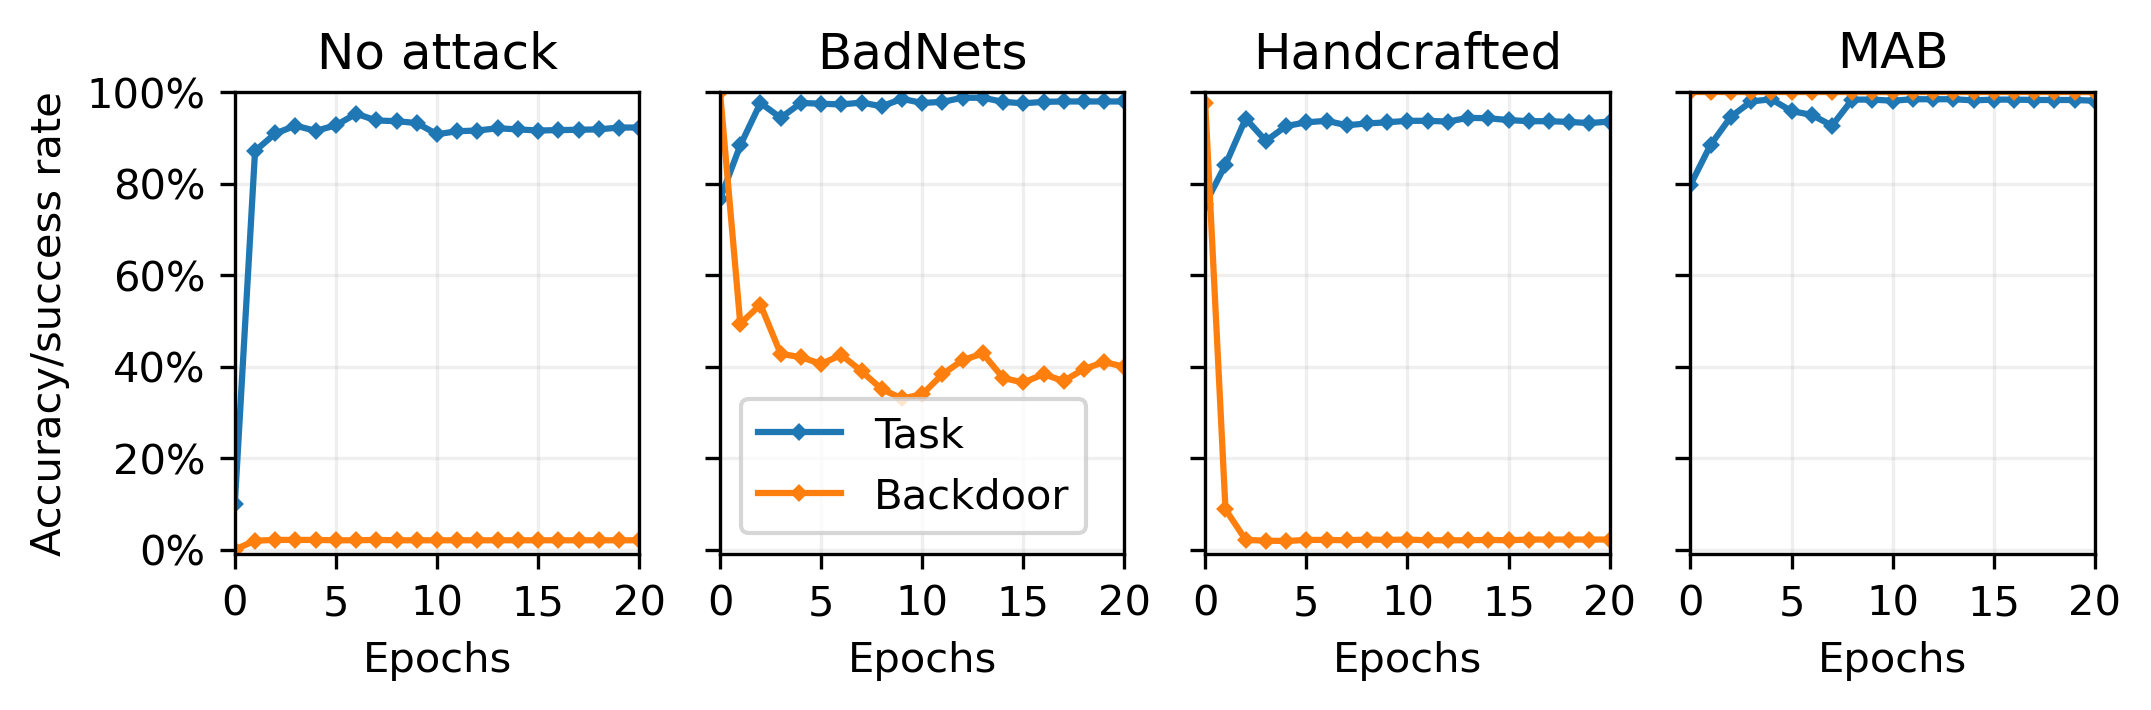

In [41]:
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams['figure.dpi'] = 300

fig, ax = plt.subplots(1, 4, sharey=True, figsize=(8, 2))

for i, df in enumerate([tm2_btsc_clean_ex, tm2_btsc_badnet_ex, tm2_btsc_hc_ex, tm2_btsc_evil_ex]):
    ax[i].plot(df['test_eval_acc'], label='Task', marker='D', markersize=2)
    ax[i].plot(df['test_bd_acc'], label='Backdoor', marker='D', markersize=2)
    ax[i].set_xlim(0, 20)
    #ax[i].set_xticks([0, 2, 4, 6, 8, 10])
    ax[i].set_xticks([0, 5, 10, 15, 20])
    ax[i].set_xlabel('Epochs')
    
    ax[i].grid(alpha=0.2)

# ax[0].plot(tm2_btsc_clean_ex['test_eval_acc'])
# ax[0].plot(tm2_btsc_clean_ex['test_bd_acc'])
# ax[0].set_xlim(0, 10)

# ax[1].plot(tm2_btsc_badnet_ex['test_eval_acc'])
# ax[1].plot(tm2_btsc_badnet_ex['test_bd_acc'])
# ax[1].set_xlim(0, 10)

# ax[2].plot(tm2_btsc_hc_ex['test_eval_acc'])
# ax[2].plot(tm2_btsc_hc_ex['test_bd_acc'])
# ax[2].set_xlim(0, 10)

ax[0].set_title('No attack')
ax[1].set_title('BadNets')
ax[2].set_title('Handcrafted')
ax[3].set_title('MAB')

ax[0].set_ylim(-0.01, 1)
ax[0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
ax[0].set_yticklabels(['0%', '20%', '40%', '60%', '80%', '100%'])
ax[0].set_ylabel('Accuracy/success rate')

ax[1].legend()
plt.savefig('./tm2_epochs.pdf',bbox_inches='tight')